In [ ]:
!pip install diptest
!pip install deep-translator

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.1/238.1 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 2.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from deep_translator import GoogleTranslator
translator = GoogleTranslator(source='auto', target='es')
from collections import Counter
import ast
import matplotlib.cm as cm

from google.colab import drive
drive.mount('/content/drive')
# Dataset is now stored in a Pandas Dataframe
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/indeed_job_dataset_clean.csv')
L = ['Unnamed: 0', 'Unnamed: 0.1']
df.drop(L, inplace=True, axis=1)
#df.columns
#desactivamos los grid para todos los graficos
plt.rcParams['axes.grid'] = False

Mounted at /content/drive


In [ ]:
# Removemos las columnas que expanden otras
df = df.drop(columns=['Date_Since_Posted', 'python', 'sql', 'machine learning', 'r', 'hadoop', 'tableau', 'sas', 'spark', 'java', 'Others'])
df = df.drop(columns=['CA', 'NY', 'VA', 'TX', 'MA', 'IL', 'WA', 'MD', 'DC', 'NC', 'Other_states'])
df = df.drop(columns=['Consulting and Business Services', 'Internet and Software', 'Banks and Financial Services', 'Health Care', 'Insurance', 'Other_industries'])
#traducimos los tipos de trabajo
df['Job_Type'] = df['Job_Type'].replace({
    'data_analyst': 'Analista de datos',
    'data_scientist': 'Científico de datos',
    'data_engineer': 'Ingeniero de datos'
})
#Este código renombrará las columnas en el DataFrame usando el diccionario de traducción
nombres_traducidos = {
    'Job_Title': 'Titulo del Trabajo',
    'Queried_Salary': 'Invervalo salarial',
    'Job_Type': 'Perfil de trabajo',
    'Skill': 'Habilidades',
    'No_of_Skills': 'Cantidad de habilidades',
    'Company': 'Empresa',
    'No_of_Reviews': 'Cantidad de reseñas',
    'No_of_Stars': 'Promedio del número de estrellas',
    'Description': 'Descripcion',
    'Location': 'Ubicación',
    'Company_Revenue': 'Ingresos de la Empresa',
    'Company_Employees': 'N° de empleados',
    'Company_Industry': 'Industria de la empresa'
}
df = df.rename(columns=nombres_traducidos)
# Aplicar la traducción a la columna 'Ingresos de la Empresa'
traduccion_ingresos = {
    'More than $10B (USD)': 'Más de 10B',
    'Less than $1B (USD)': 'Menos de 1B',
    '$1B to $5B (USD)': '1B a 5B',
    '$5B to $10B (USD)': '5B a 10B',
}
df['Ingresos de la Empresa'] = df['Ingresos de la Empresa'].map(traduccion_ingresos)
# Aplicar la traducción a la columna 'N° de empleados'
traduccion_nempleados = {
    '10,000+': '>10000+',
    'Less than 10,000': '<10000'
}
df['N° de empleados'] = df['N° de empleados'].map(traduccion_nempleados)

#Convertir todas las empresas, habilidades, ubicacion a minuscula
df['Empresa'] = df['Empresa'].str.lower()
df['Habilidades'] = df['Habilidades'].str.lower()
df['Ubicación'] = df['Ubicación'].str.lower()
df['Titulo del Trabajo'] = df['Titulo del Trabajo'].str.lower()
# contabilizamos las propuestas laborales duplicadas, aquellas que coinciden en 'Empresa', 'Habilidades', 'Titulo del Trabajo', 'Descripcion' y 'Ubicación'
df = df.drop_duplicates(subset=['Empresa', 'Habilidades', 'Titulo del Trabajo', 'Descripcion', 'Ubicación'], keep='first')
# Reemplazamos / imputamos los valores NaN del Promedio del número de estrellas / reseñas
df['Promedio del número de estrellas'].fillna(df['Promedio del número de estrellas'].mean(), inplace=True) # reemplazamos por media
df['Cantidad de reseñas'].fillna(0, inplace=True) # reemplazamos por 0
#validamos si existen valores NaN en el dataframe
print(df.isnull().values.any())

True


/tmp/ipykernel_775/3369646023.py:51: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Promedio del número de estrellas'].fillna(df['Promedio del número de estrellas'].mean(), inplace=True) # reemplazamos por media
/tmp/ipykernel_775/3369646023.py:52: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beha

Graficos realizados:
Gráfico ?. Empresas e industrias con mayor demanda de profesionales en el mercado laboral. Periodo octubre - noviembre de 2022.

Gráfico ?. Distribución de oportunidades laborales por Perfil de trabajo en el sector de datos. Periodo octubre - noviembre de 2022.

Gráfico ?. Distribución de Rangos Salariales. Periodo octubre - noviembre de 2022.

Gráfico ?. Distribución de Rangos Salariales por Perfil de Trabajo. Periodo octubre - noviembre de 2022.

Gráfico ?. Distribución del número de habilidades por Perfil de trabajo. Periodo octubre - noviembre de 2022.

Gráfico ?. Frecuencia de habilidades solicitadas por Perfil de trabajo para perfiles orientados a datos. Periodo octubre - noviembre de 2022.

Gráfico ?. Distribución del promedio de número de empleados por tipo de trabajo. Periodo octubre - noviembre de 2022.

Gráfico ?. Distribución de los ingresos anuales de las empresas que requieren profesionales de Datos. Periodo octubre - noviembre de 2022.



In [ ]:
# @title Número de valores nulos por campo
num_valores_nan = df.isna().sum()
num_valores_nan

,0
Titulo del Trabajo,0
Link,0
Invervalo salarial,0
Perfil de trabajo,0
Habilidades,182
Cantidad de habilidades,0
Empresa,69
Cantidad de reseñas,0
Promedio del número de estrellas,0
Descripcion,0


# 1. Descripción estadística

In [ ]:
# @title Descripcion de 'Empresa', 'Titulo del Trabajo', 'Invervalo salarial', 'Perfil de trabajo', 'Ubicación', 'Ingresos de la Empresa', 'N° de empleados', 'Industria de la empresa'
descripcion_empresa = df[['Empresa', 'Titulo del Trabajo', 'Invervalo salarial', 'Perfil de trabajo', 'Ubicación', 'Ingresos de la Empresa', 'N° de empleados', 'Industria de la empresa']].describe()
print(descripcion_empresa)

                    Empresa Titulo del Trabajo Invervalo salarial  \
count                  5007               5076               5076   
unique                 2091               2164                  6   
top     booz allen hamilton     data scientist      100000-119999   
freq                    125                641               1232   

          Perfil de trabajo Ubicación Ingresos de la Empresa N° de empleados  \
count                  5076      4875                   1774            2833   
unique                    3        51                      4               2   
top     Científico de datos        ca             Más de 10B         >10000+   
freq                   2279      1276                    903            1740   

                 Industria de la empresa  
count                               3367  
unique                                33  
top     Consulting and Business Services  
freq                                 623  


In [ ]:
# @title Habilidades unicas: moda y frecuencia
# Convertir la serie a cadena de texto
df['Habilidades'] = df['Habilidades'].astype(str)

#habilidades unicas
habilidades_unicas = set(df['Habilidades'].str.replace('[','').str.replace(']','').str.split(', ').sum())

# Separar los elementos entre '[' y ']'
hab_sep = df['Habilidades'].str.replace('[','').str.replace(']','')

# Contabilizar la cantidad de habilidades
hab_cant = hab_sep.str.split(', ').apply(len)

# Calcular la moda y su frecuencia
moda = hab_sep.str.split(', ', expand=True).stack().mode()
frecuencia_moda = hab_sep.str.split(', ', expand=True).stack().value_counts().max()

print("Habilidades unicas:")
print(len(habilidades_unicas))
print("\nModa de habilidades:", moda)
print("Frecuencia de la moda:", frecuencia_moda)

Habilidades unicas:
464

Moda de habilidades: 0    'python'
dtype: object
Frecuencia de la moda: 3000


In [ ]:
# @title Cantidad promedio de busquedas laborales por empresa
#Promedio de observaciones por empresa
registros_por_empresa = df.groupby('Empresa').size()
# Calcula el promedio de registros por empresa
promedio_registros_por_empresa = registros_por_empresa.mean()
print("Promedio de busquedas laborales por empresa:", promedio_registros_por_empresa)

Promedio de busquedas laborales por empresa: 2.39454806312769


In [ ]:
# @title Descripcion estadistica de las variables numericas
# Imprimir la descripción
print(df[['Promedio del número de estrellas', 'Cantidad de reseñas', 'Cantidad de habilidades']].describe())

       Promedio del número de estrellas  Cantidad de reseñas  \
count                       5076.000000          5076.000000   
mean                           3.840977          3361.106186   
std                            0.379586         15688.912167   
min                            1.300000             0.000000   
25%                            3.700000             7.000000   
50%                            3.840977           149.000000   
75%                            4.000000          1733.000000   
max                            5.000000        157475.000000   

       Cantidad de habilidades  
count              5076.000000  
mean                  7.909968  
std                   5.054927  
min                   0.000000  
25%                   4.000000  
50%                   7.000000  
75%                  11.000000  
max                  20.000000  


In [ ]:
# @title  coeficiente de variación (CV)
medias = df[['Promedio del número de estrellas', 'Cantidad de reseñas', 'Cantidad de habilidades']].mean()
desviaciones_estandar = df[['Promedio del número de estrellas', 'Cantidad de reseñas', 'Cantidad de habilidades']].std()
# Calcular el coeficiente de variación
coeficientes_variacion = desviaciones_estandar / medias
print(coeficientes_variacion)

Promedio del número de estrellas    0.098825
Cantidad de reseñas                 4.667782
Cantidad de habilidades             0.639058
dtype: float64


In [ ]:
# @title  Contar los elementos donde 'Cantidad de habilidades' es 0
(df['Cantidad de habilidades'] == 0).sum()

np.int64(182)

In [ ]:
# @title  Contar los elementos donde 'Promedio del número de estrellas' es 5
(df['Promedio del número de estrellas'] == 5).sum()

np.int64(28)

# Exploración de variables categóricas


In [ ]:
# @title exploracion de la empresa en si

# Frecuencia y moda de la empresa
frecuencia = df['Empresa'].value_counts()
moda = df['Empresa'].mode()
print("Frecuencia de cada categoría:" , frecuencia)
print("\nModa:", moda)
# ----------------------------------------------------------------------------------------------------------------------------------
# Diez empresas de mayor demanda
top_employers = df['Empresa'].value_counts().head(10)
# Listamos las 10 empresas más recurrentes
empresas_mas_recurrentes = top_employers.index
# Filtramos el DataFrame para incluir solo las 10 empresas más recurrentes
df_top_empresas = df[df['Empresa'].isin(empresas_mas_recurrentes)]
# Agrupamos por empresa y obtenemos las industrias únicas para cada una
industrias_por_empresa = df_top_empresas.groupby('Empresa')['Industria de la empresa'].unique()

for i in range(len(top_employers)):
    industria = industrias_por_empresa.loc[top_employers.index.values[i]]
    trad = translator.translate(str(industria[0]))  # No necesita .text
    top_employers.index.values[i] = top_employers.index.values[i] + " \n (" + trad + ")"

plt.figure(figsize=(10, 6))
sns.barplot(x=top_employers.values, y=top_employers.index, palette='viridis', hue=top_employers.index)
#plt.title('Top 10 Empleadores por Cantidad de Ofertas de Trabajo')
plt.xlabel('Frecuencia de propuestas laborales publicadas', fontsize=15)
plt.ylabel('Empresa', fontsize=15)
plt.show()

Frecuencia de cada categoría: Empresa
booz allen hamilton                                125
harnham                                             83
facebook                                            63
kpmg llp                                            62
walmart                                             48
                                                  ... 
big fish games                                       1
system1                                              1
dialpad, inc.                                        1
veteran's enterprise technology solutions, inc.      1
vistaprint                                           1
Name: count, Length: 2091, dtype: int64

Moda: 0    booz allen hamilton
Name: Empresa, dtype: object


TooManyRequests: Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function

In [ ]:
# @title Porcentajes de empleador e industria
# Obtener el primer empleador del top 10 usando el índice original (sin traducción añadida)
primer_empleador = top_employers.index[0].split("\n")[0].strip()  # Eliminar la traducción si fue agregada
# Total de ofertas laborales en el dataset
total_ofertas = df['Empresa'].count()
# Cantidad de ofertas publicadas por el primer empleador
ofertas_primer_empleador = top_employers.iloc[0]
# Calcular el porcentaje de ofertas del primer empleador sobre el total
porcentaje_ofertas = (ofertas_primer_empleador / total_ofertas) * 100
# Obtener la industria del primer empleador usando el nombre original
industria_primer_empleador = industrias_por_empresa.loc[primer_empleador][0]
# Total de industrias únicas en el dataset
total_industrias = df['Industria de la empresa'].nunique()
# Cantidad de ofertas en la industria del primer empleador
ofertas_industria_primer_empleador = df[df['Industria de la empresa'] == industria_primer_empleador].shape[0]
# Calcular el porcentaje de la industria del primer empleador sobre el total de ofertas
porcentaje_industria = (ofertas_industria_primer_empleador / total_ofertas) * 100
# Mostrar resultados
print(f"El primer empleador: '{primer_empleador}'")
print(f"Cantidad de empresas ofertantes: {df['Empresa'].nunique()}")
print(f"Cantidad de propuestas presentadas por el primer empleador: {ofertas_primer_empleador}")
print(f"Total de ofertas laborales en el dataset: {total_ofertas}")
print(f"Porcentaje de ofertas del primer empleador sobre el total: {porcentaje_ofertas:.2f}%\n")

print(f"Industria del primer empleador: '{industria_primer_empleador}'")
print(f"Cantidad de ofertas en esta industria: {ofertas_industria_primer_empleador}")
print(f"Total de industrias únicas en el dataset: {total_industrias}")
print(f"Porcentaje de ofertas en la industria del primer empleador sobre el total: {porcentaje_industria:.2f}%")


El primer empleador: 'booz allen hamilton'
Cantidad de empresas ofertantes: 2091
Cantidad de propuestas presentadas por el primer empleador: 125
Total de ofertas laborales en el dataset: 5007
Porcentaje de ofertas del primer empleador sobre el total: 2.50%

Industria del primer empleador: 'Consulting and Business Services'
Cantidad de ofertas en esta industria: 623
Total de industrias únicas en el dataset: 33
Porcentaje de ofertas en la industria del primer empleador sobre el total: 12.44%


/tmp/ipykernel_775/1213549748.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_df = df.pivot_table(index='Invervalo salarial', columns='Perfil de trabajo', aggfunc='size', fill_value=0)


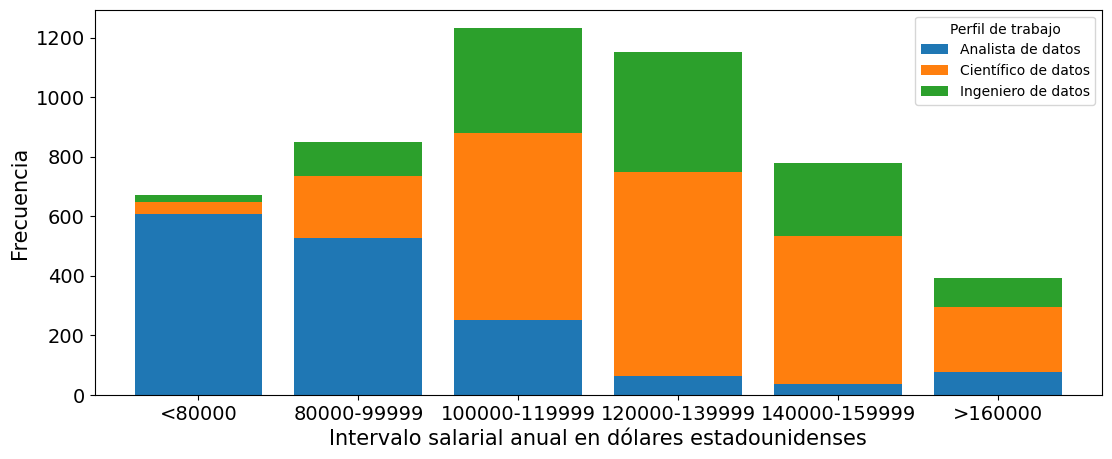

5076


In [ ]:
# @title Queried_Salary by job type
# Definir el orden deseado
order = ['<80000', '80000-99999', '100000-119999', '120000-139999', '140000-159999', '>160000']

# Asegurarse de que todos los valores en 'Invervalo salarial' estén en 'order'
df = df[df['Invervalo salarial'].isin(order)]
# Crear una copia del DataFrame con la columna 'Invervalo salarial' como categoría ordenada
df['Invervalo salarial'] = pd.Categorical(df['Invervalo salarial'], categories=order, ordered=True)
# Crear tabla de frecuencias con el orden específico
pivot_df = df.pivot_table(index='Invervalo salarial', columns='Perfil de trabajo', aggfunc='size', fill_value=0)
# Configurar el tamaño del gráfico
pivot_df.plot(kind='bar', stacked=True, figsize=(13, 5), width=0.8)
# Configuración del título y etiquetas del gráfico
#plt.title('Distribución de Rangos Salariales por Perfil de Trabajo')
plt.xlabel('Intervalo salarial anual en dólares estadounidenses', fontsize=15)
plt.ylabel('Frecuencia', fontsize=15)
plt.xticks(fontsize=14, rotation=0, ha='center')
plt.yticks(fontsize=14)
plt.show()

total_observaciones = pivot_df.values.sum()
print(total_observaciones)

/tmp/ipykernel_775/3307715040.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


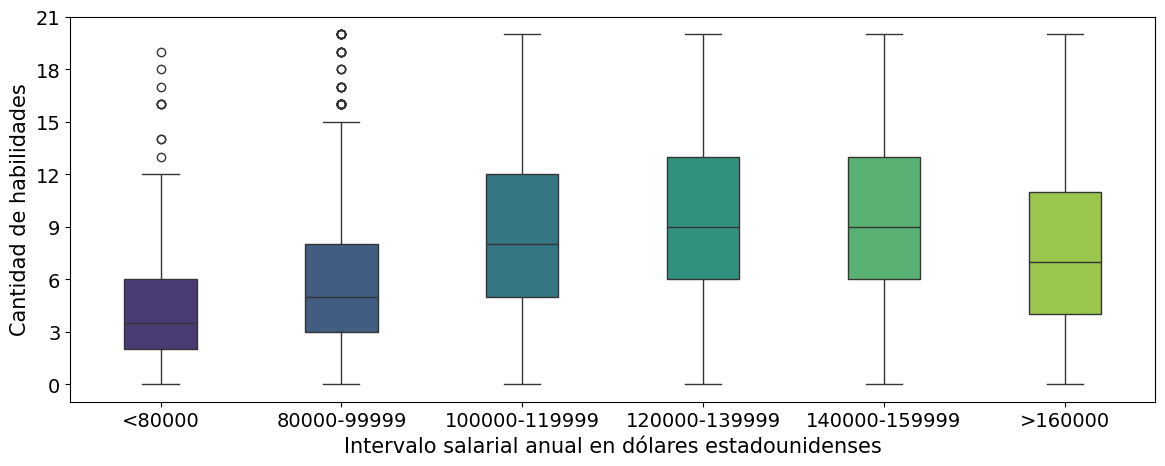

5076


In [ ]:
from matplotlib.ticker import MaxNLocator

# @title Distribución del Número de Habilidades por Invervalo salarial
# Crear una copia del DataFrame original
df_copy = df.copy()
# Filtramos observaciones que no tengan 'Invervalo salarial' nulo
df_copy = df_copy.dropna(subset=['Invervalo salarial'])
# Graficamos el box plot
plt.figure(figsize=(14, 5))
sns.boxplot(data=df_copy, x='Invervalo salarial', y='Cantidad de habilidades', hue='Invervalo salarial', palette='viridis', dodge=False, width=0.4)
#plt.title('Distribución del Cantidad de habilidades por Invervalo salarial')
plt.xlabel('Intervalo salarial anual en dólares estadounidenses', fontsize=15)
plt.ylabel('Cantidad de habilidades', fontsize=15)
plt.xticks(fontsize=14, rotation=0, ha='center')
plt.yticks(fontsize=14)
plt.legend().set_visible(False)
ax = plt.gca()  # obtiene los ejes actuales
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()

total_observaciones = df_copy[df_copy['Invervalo salarial'].isin(order)]['Cantidad de habilidades'].notna().sum()
print(total_observaciones)

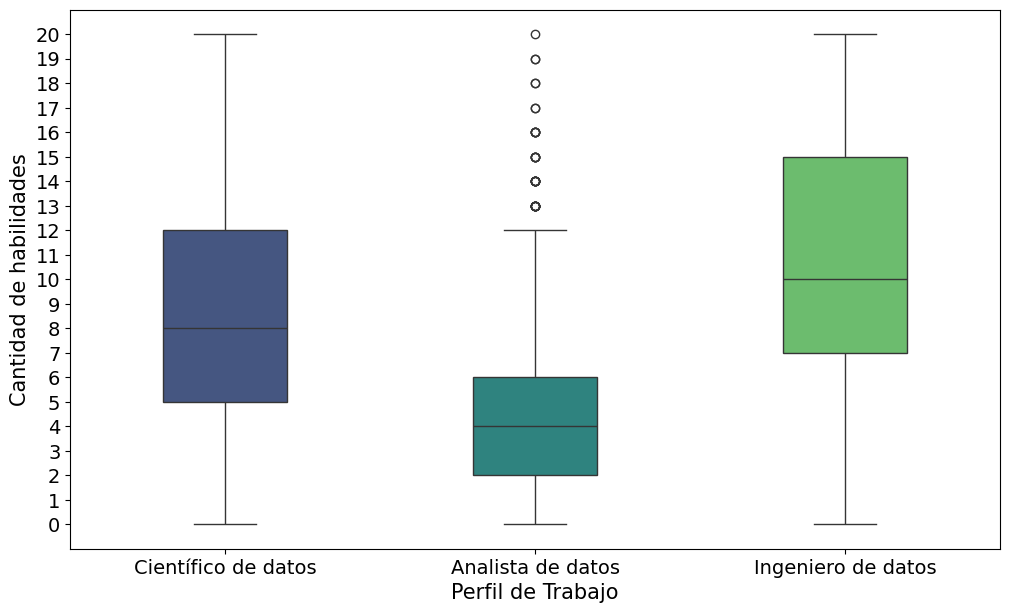

Total de observaciones en el gráfico: 5076


In [ ]:
# @title Distribución del Cantidad de habilidades por Perfil de Trabajo
#Box Plot: Comparar la distribución de Cantidad de habilidades requeridas entre diferentes Perfiles de trabajo.
y_min = int(df['Cantidad de habilidades'].min())  # Valor mínimo
y_max = int(df['Cantidad de habilidades'].max())  # Valor máximo
plt.figure(figsize=(12, 7))
sns.boxplot(data=df, x='Perfil de trabajo', y='Cantidad de habilidades', hue='Perfil de trabajo', palette='viridis', dodge=False, width=0.4)
plt.xticks(rotation=90)
plt.xlabel('Perfil de Trabajo', fontsize=15)
plt.ylabel('Cantidad de habilidades', fontsize=15)
plt.xticks(fontsize=14, rotation=0, ha='center')
plt.yticks(fontsize=14)
# Ajustar escala del eje Y a números enteros
plt.yticks(range(y_min, y_max + 1))
# Ocultar la leyenda
plt.legend([], [], frameon=False)
plt.show()

total_cant_hab = df['Cantidad de habilidades'].notna().sum()
total_perf = df['Perfil de trabajo'].notna().sum()
print("Total de observaciones en el gráfico:", min(total_cant_hab, total_perf))

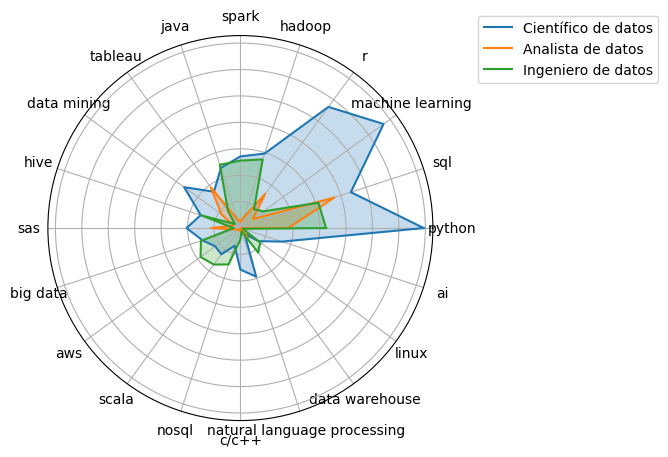

Total de observaciones en el gráfico: 4894


In [ ]:
# @title Gráfico de Radar para comparar la presencia de diferentes habilidades en varios tipos de trabajo
# Muestra la distribución de habilidades en un formato radial, comparando varias categorías en un solo gráfico.
# Crear una copia del DataFrame original
df_copy = df.copy()
# Reemplazar la cadena "nan" por np.nan en la copia
df_copy['Habilidades'] = df_copy['Habilidades'].replace('nan', np.nan)
# Limpiar los datos
df_copy['Habilidades'] = df_copy['Habilidades'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df_copy.dropna(subset=['Habilidades', 'Perfil de trabajo'], inplace=True)
# Crear un DataFrame vacío para almacenar frecuencias
df_frecuencias = pd.DataFrame()
# Filtrar y contar las habilidades por Perfil de trabajo
for tipo in df_copy['Perfil de trabajo'].unique():
    df_tipo = df_copy[df_copy['Perfil de trabajo'] == tipo]
    # Desagregar las habilidades
    habilidades = [habilidad for sublist in df_tipo['Habilidades'] for habilidad in sublist]
    # Contar frecuencia de habilidades
    conteo_habilidades = Counter(habilidades)
    # Convertir a DataFrame
    df_tipo_frecuencias = pd.DataFrame(conteo_habilidades.items(), columns=['Habilidad', 'Frecuencia'])
    df_tipo_frecuencias['Perfil de trabajo'] = tipo
    # Concatenar al DataFrame de frecuencias
    df_frecuencias = pd.concat([df_frecuencias, df_tipo_frecuencias])
# Obtener las 20 habilidades más frecuentes en general
top_habilidades = df_frecuencias.groupby('Habilidad')['Frecuencia'].sum().nlargest(20).index
df_top_habilidades = df_frecuencias[df_frecuencias['Habilidad'].isin(top_habilidades)]
# Función para graficar radar
def radar_chart(data_dict, labels, title):
    num_vars = len(labels)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # Repetir el primer valor para cerrar el gráfico
    fig, ax = plt.subplots(figsize=(10, 5), subplot_kw=dict(polar=True))
    # Graficar cada Perfil de trabajo en el mismo gráfico
    for tipo, values in data_dict.items():
        data = values + values[:1]  # Repetir el primer valor para cerrar el gráfico
        ax.plot(angles, data, label=tipo)
        ax.fill(angles, data, alpha=0.25)
    ax.set_yticklabels([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    #plt.title(title, size=15, color='blue', y=1.1)
    plt.legend(loc='upper left', bbox_to_anchor=(1.10, 1.07))
    plt.show()
# Preparar los datos para el gráfico de radar
labels = list(top_habilidades)
data_dict = {}
for tipo in df_copy['Perfil de trabajo'].unique():
    df_tipo_frecuencias = df_top_habilidades[df_top_habilidades['Perfil de trabajo'] == tipo]
    values = [df_tipo_frecuencias[df_tipo_frecuencias['Habilidad'] == habilidad]['Frecuencia'].sum() for habilidad in labels]
    # Asegurar que la lista de valores tenga la misma longitud que labels
    if len(values) < len(labels):
        values += [0] * (len(labels) - len(values))
    data_dict[tipo] = values
# Graficar el radar para los tres tipos de trabajo en un solo gráfico
radar_chart(data_dict, labels, 'Comparación de habilidades entre tipos de trabajo')


total_observaciones = len(df_copy.index)
print("Total de observaciones en el gráfico:", total_observaciones)

In [ ]:
# Porfentaje de habilidades segun cada perfil

from collections import Counter
import pandas as pd

resultados_top5 = []

for perfil in df_copy['Perfil de trabajo'].unique():

    # Filtrar el perfil
    df_perfil = df_copy[
        df_copy['Perfil de trabajo'] == perfil
    ]

    # Obtener todas las habilidades del perfil
    habilidades = [
        habilidad
        for lista in df_perfil['Habilidades']
        for habilidad in lista
    ]

    # Contar recurrencias
    conteo = Counter(habilidades)

    # Total de recurrencias de TODAS las habilidades del perfil
    total_recurrencias = sum(conteo.values())

    # Cinco habilidades más recurrentes
    top_5 = conteo.most_common(5)

    # Recurrencias acumuladas de las Top 5
    recurrencias_top5 = sum(freq for _, freq in top_5)

    # Porcentaje que representan las Top 5
    porcentaje_top5 = (
        recurrencias_top5 / total_recurrencias * 100
    )

    # Guardar resultados
    resultados_top5.append({
        'Perfil': perfil,
        'Top 5 habilidades': ', '.join(
            habilidad for habilidad, _ in top_5
        ),
        'Recurrencias Top 5': recurrencias_top5,
        'Recurrencias totales': total_recurrencias,
        'Porcentaje Top 5': round(porcentaje_top5, 2)
    })

df_top5 = pd.DataFrame(resultados_top5)

print(df_top5.to_string(index=False))

             Perfil                        Top 5 habilidades  Recurrencias Top 5  Recurrencias totales  Porcentaje Top 5
Científico de datos python, machine learning, r, sql, hadoop                6667                 19596             34.02
  Analista de datos             sql, tableau, python, r, sas                2541                  7182             35.38
 Ingeniero de datos         python, sql, hadoop, spark, java                3538                 13373             26.46


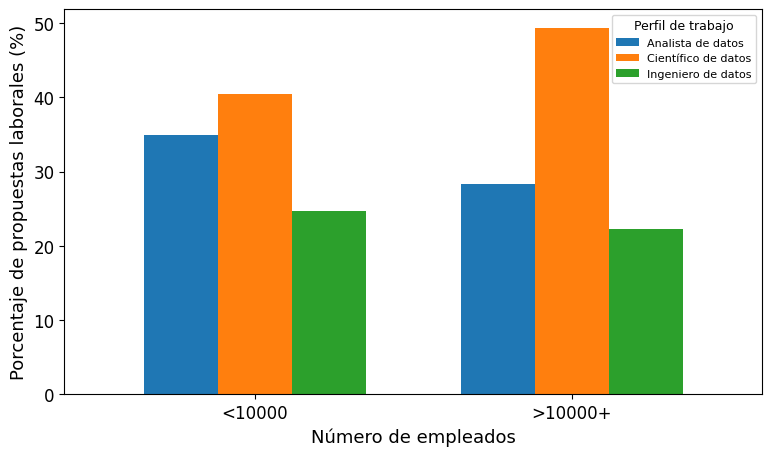

Cantidad de empresas que han publicado su número de empleados: 823
Cantidad de observaciones utilizadas en el gráfico (no nulas): 2234
Total observaciones no nulas: 2234
>10000+ : 1318 observaciones (59.00%)
<10000  : 916 observaciones (41.00%)
Cientificos de datos dentro del grupo >10000+ : 651 (49.39%)


In [ ]:
# @title Numero de empleados segun Perfil de trabajo
# Agrupamos por 'Empresa', 'Titulo del Trabajo', 'N° de empleados', 'Perfil de trabajo'
# Con el objetivo de filtrar propuestas duplicadas por parte de una empresa para el mismo puesto
# y que no se sesgue el numero de empleados por Perfil de trabajo
grouped_df_empresa_titulo = df.groupby(['Empresa', 'Titulo del Trabajo', 'N° de empleados', 'Perfil de trabajo']).size().reset_index(name='Frecuencia')

pct_df = pd.crosstab(
    grouped_df_empresa_titulo['N° de empleados'],
    grouped_df_empresa_titulo['Perfil de trabajo'],
    normalize='index'
) * 100

# Graficar porcentajes
ax = pct_df.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.7
)

plt.xlabel('Número de empleados', fontsize=13)
plt.ylabel('Porcentaje de propuestas laborales (%)', fontsize=13)
plt.xticks(fontsize=12, rotation=0, ha='center')
plt.yticks(fontsize=12)
plt.legend(title='Perfil de trabajo', fontsize=8, title_fontsize=9)

plt.show()

# Contar cuántas empresas han publicado su número de empleados (excluyendo valores nulos)
num_empresas_con_empleados = df[df['N° de empleados'].notna()]['Empresa'].nunique()
# Imprimir el resultado
print(f"Cantidad de empresas que han publicado su número de empleados: {num_empresas_con_empleados}")
# Contar observaciones NO nulas de "N° de empleados" utilizadas en el gráfico
observaciones_no_nulas = grouped_df_empresa_titulo['N° de empleados'].notna().sum()
print("Cantidad de observaciones utilizadas en el gráfico (no nulas):", observaciones_no_nulas)
# Cantidad por categoría de empleados
count_mayor_10000 = (grouped_df_empresa_titulo['N° de empleados'] == '>10000+').sum()
count_menor_10000 = (grouped_df_empresa_titulo['N° de empleados'] == '<10000').sum()

# Porcentajes por categoría
pct_mayor_10000 = 100 * count_mayor_10000 / observaciones_no_nulas
pct_menor_10000 = 100 * count_menor_10000 / observaciones_no_nulas

print(f"Total observaciones no nulas: {observaciones_no_nulas}")
print(f">10000+ : {count_mayor_10000} observaciones ({pct_mayor_10000:.2f}%)")
print(f"<10000  : {count_menor_10000} observaciones ({pct_menor_10000:.2f}%)")

# Porcentaje del perfil 'Científico de datos' dentro del grupo >10000+
grupo_mayor_10000 = grouped_df_empresa_titulo[
    grouped_df_empresa_titulo['N° de empleados'] == '>10000+'
]

total_mayor_10000 = len(grupo_mayor_10000)
cientificos_en_mayor = (grupo_mayor_10000['Perfil de trabajo'] == 'Científico de datos').sum()

pct_cientificos_mayor = 100 * cientificos_en_mayor / total_mayor_10000

print(f'Cientificos de datos dentro del grupo >10000+ : {cientificos_en_mayor} ({pct_cientificos_mayor:.2f}%)')


Cantidad de empresas que han publicado sus ingresos anuales 480


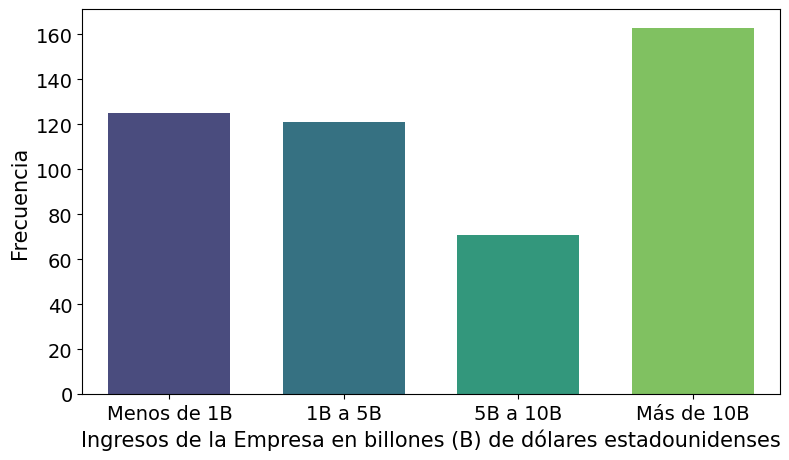

In [ ]:
# @title Distribucion de los ingresos de la empresa en dolares
order_Ingresos = ['Menos de 1B', '1B a 5B', '5B a 10B', 'Más de 10B']
plt.figure(figsize=(9, 5))
#unica observacion por empresa con ingresos publicados
df_unique = df.dropna(subset=['Ingresos de la Empresa']).drop_duplicates(subset='Empresa')
#cantidad de empresas que han publicado sus ingresos anuales
print("Cantidad de empresas que han publicado sus ingresos anuales", df_unique["Empresa"].count())
# Obtener la frecuencia de ingresos en el orden establecido
frecuencia_Ingresos = df_unique['Ingresos de la Empresa'].value_counts().loc[order_Ingresos]
# Crear un dataframe temporal para facilitar el uso de 'hue'
temp_df = pd.DataFrame({'Ingresos de la Empresa': frecuencia_Ingresos.index, 'Frecuencia': frecuencia_Ingresos.values})
# Graficar el diagrama de barras con el orden establecido y paleta viridis
sns.barplot(data=temp_df, x='Ingresos de la Empresa', y='Frecuencia', hue='Ingresos de la Empresa',
            palette='viridis', dodge=False, legend=False, width=0.7)
plt.xlabel('Ingresos de la Empresa en billones (B) de dólares estadounidenses', fontsize=15)
plt.ylabel('Frecuencia', fontsize=15)
plt.xticks(fontsize=14, rotation=0, ha='center')
plt.yticks(fontsize=14)
plt.show()

# Exploración de variables numéricas

In [ ]:
# Campos cuyo numero de habilidades esta sin completar (es 0)
(df["Cantidad de habilidades"] == 0).sum()

np.int64(182)

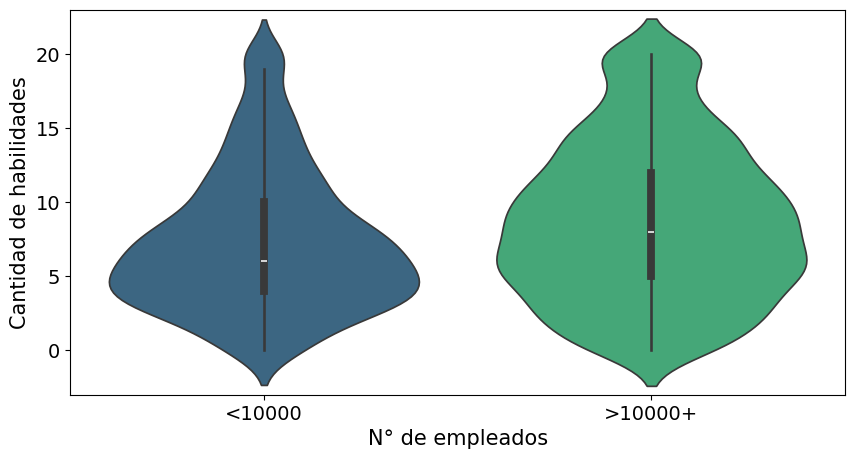

                  count      mean       std  min  25%  50%   75%   max
N° de empleados                                                       
<10000           1093.0  7.315645  4.736278  0.0  4.0  6.0  10.0  20.0
>10000+          1740.0  8.704598  5.337498  0.0  5.0  8.0  12.0  20.0
Total de observaciones en el gráfico: 2833
Coeficiente de variación para empresas <10000: 0.6474176758212433
Coeficiente de variación para empresas >10000: 0.6131814212014601


/tmp/ipykernel_775/1059234134.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  estadisticas_por_grupo = df.groupby('N° de empleados')['Cantidad de habilidades'].describe()


In [ ]:
# Gráfico de violin sin advertencia
plt.figure(figsize=(10, 5))
df['N° de empleados'] = pd.Categorical(
    df['N° de empleados'],
    categories=['<10000', '>10000+'],
    ordered=True
)
sns.violinplot(x='N° de empleados', y='Cantidad de habilidades', hue='N° de empleados', data=df, palette='viridis', legend=False)
# Títulos y etiquetas
#plt.title('Distribución de Cantidad de habilidades según N° de empleados')
plt.xlabel('N° de empleados', fontsize=15)
plt.ylabel('Cantidad de habilidades', fontsize=15)
plt.xticks(fontsize=14, rotation=0, ha='center')
plt.yticks(fontsize=14)
plt.ylim(-3, 23)
plt.show()
# Agrupar las estadísticas por 'N° de empleados'
estadisticas_por_grupo = df.groupby('N° de empleados')['Cantidad de habilidades'].describe()
# Imprimir las estadísticas comparativas
print(estadisticas_por_grupo)
total_hab = df['Cantidad de habilidades'].notna().sum()
total_nro_emp = df['N° de empleados'].notna().sum()
print("Total de observaciones en el gráfico:", min(total_hab, total_nro_emp))
# Empresas <10000
media_menor = estadisticas_por_grupo.loc['<10000', 'mean']
desvio_menor = estadisticas_por_grupo.loc['<10000', 'std']

# Empresas >10000
media_mayor = estadisticas_por_grupo.loc['>10000+', 'mean']
desvio_mayor = estadisticas_por_grupo.loc['>10000+', 'std']

# Coeficiente de variación = desvio estandar / media
cv_mayor = desvio_mayor/media_mayor
cv_menor = desvio_menor / media_menor

print("Coeficiente de variación para empresas <10000:", cv_menor)
print("Coeficiente de variación para empresas >10000:", cv_mayor)

# Relaciones

In [ ]:
# @title Coeficiente de correlacion de Pearson entre Cantidad de habilidades y Promedio del número de estrellas
correlacion = df['Cantidad de habilidades'].corr(df['Promedio del número de estrellas'])
print(f'Coeficiente de correlación: {correlacion}')

Coeficiente de correlación: 0.012412533641103535


In [ ]:
# @title Coeficiente de correlacion de Pearson entre Cantidad de habilidades y Cantidad de reseñas
correlacion = df['Cantidad de habilidades'].corr(df['Cantidad de reseñas'])
print(f'Coeficiente de correlación: {correlacion}')

Coeficiente de correlación: 0.059587697042866324


In [ ]:
# @title Coeficiente de correlacion de Pearson entre Promedio del número de estrellas y Cantidad de reseñas
correlacion = df['Promedio del número de estrellas'].corr(df['Cantidad de reseñas'])
print(f'Coeficiente de correlación: {correlacion}')

Coeficiente de correlación: -0.03777219067798184


In [ ]:
# @title Pruebas estadísticas completas (coeficiente + p-value) para analizar las correlaciones entre las 3 variables numericas

import pandas as pd
from scipy.stats import pearsonr

# Variables a analizar
vars_interes = [
    "Cantidad de habilidades",
    "Promedio del número de estrellas",
    "Cantidad de reseñas"
]

# --- 1. Matriz de correlación ---
print("=== MATRIZ DE CORRELACIÓN (Pearson) ===")
print(df[vars_interes].corr(method="pearson"), "\n")

# --- 2. Pruebas de significancia con p-value ---
print("=== PRUEBAS ESTADÍSTICAS DE CORRELACIÓN (Pearson + p-value) ===")

for i in range(len(vars_interes)):
    for j in range(i+1, len(vars_interes)):
        x = vars_interes[i]
        y = vars_interes[j]

        coef, pval = pearsonr(df[x], df[y])
        print(f"\nCorrelación entre **{x}** y **{y}**:")
        print(f"  ➤ Coeficiente r = {coef:.4f}")
        print(f"  ➤ p-value = {pval:.4g}")

        # Interpretación opcional
        if pval > 0.05:
            print("  → No se detecta una relación estadísticamente significativa (p > 0.05).")
        else:
            print("  → La relación es *estadísticamente significativa* (p < 0.05).")


=== MATRIZ DE CORRELACIÓN (Pearson) ===
                                  Cantidad de habilidades  \
Cantidad de habilidades                          1.000000   
Promedio del número de estrellas                 0.012413   
Cantidad de reseñas                              0.059588   

                                  Promedio del número de estrellas  \
Cantidad de habilidades                                   0.012413   
Promedio del número de estrellas                          1.000000   
Cantidad de reseñas                                      -0.037772   

                                  Cantidad de reseñas  
Cantidad de habilidades                      0.059588  
Promedio del número de estrellas            -0.037772  
Cantidad de reseñas                          1.000000   

=== PRUEBAS ESTADÍSTICAS DE CORRELACIÓN (Pearson + p-value) ===

Correlación entre **Cantidad de habilidades** y **Promedio del número de estrellas**:
  ➤ Coeficiente r = 0.0124
  ➤ p-value = 0.3766
  → No se